In [ ]:
# Scratch (exploratory, outside any study): V2 at margin 0 with the current support set (10 frames) and with the two
# frames of 1_disassembled_controlled_caos added (12 frames), as in the first version of the perception notebook.
import sys
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from perception.classes import CLASS_NAMES, BACKGROUND_ID, HAND_LABEL, PIECE_LABELS
from perception.features import FeatureExtractor
from perception.labels import check_annotation, rasterize_annotation, patch_label_grid
from perception.prototypes import patch_prototypes, sort_by_class, class_similarities_gpu, assign_labels
from perception.metrics import (confusion_matrix, frame_iou, frame_miou, bootstrap_miou, percentile_interval,
                                MERGED_NAMES)
from perception.visualization import render_overlay
from utils.continuous_analysis import analyse, load_events

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
FRAMES_DIR = PROJECT_ROOT / "data" / "extracted_frames"
VIDEO_PATH = PROJECT_ROOT / "data" / "raw_videos" / "assembly_2.mp4"
EVENTS_PATH = PROJECT_ROOT / "configs" / "assembly_2_events.json"
MARGIN_STUDY_DIR = PROJECT_ROOT / "outputs" / "phase_1_margin_study"
OUT_DIR = PROJECT_ROOT / "outputs" / "scratch" / "support_swap"
OUT_DIR.mkdir(parents=True, exist_ok=True)

MARGIN = 0.0                 # decided for V2 by the margin study (Section 6)
MIN_LABEL_COVERAGE = 0.5     # labelling rule of the pipeline (Section 5)
N_BOOTSTRAP, SEED = 1000, 0

CURRENT = [                  # support set of the multi-prototype and margin studies
    ("5_assembled_f0002", PIECE_LABELS), ("caos_f0149", PIECE_LABELS), ("5_assembled_f0019", PIECE_LABELS),
    ("3_disassembled_ordered_f0001", PIECE_LABELS - {"base"}), ("2_disassembled_caos_f0016", PIECE_LABELS - {"base"}),
    ("Take_3_1_Base_f0099", {"base"}), ("Take_3_1_Base_f0131", {"base"}), ("caos_f0211", {HAND_LABEL}),
    ("4_partially_assembled_f0002", {"body", "mouth"}), ("caos_f0043", {"mouth"}),
]
ADDED = [("1_disassembled_controlled_caos_f0001", PIECE_LABELS - {"base"}),   # base out of definition here, as in validation
         ("1_disassembled_controlled_caos_f0016", PIECE_LABELS - {"base"})]
SUPPORTS = {"10 frames (current)": CURRENT, "12 frames (+ 1_disassembled_controlled_caos)": CURRENT + ADDED}
EVAL_FRAMES = ["assembly_2_f0003", "assembly_2_f0017", "assembly_2_f0030",
               "assembly_2_f0046", "assembly_2_f0057", "assembly_2_f0068"]
assert not {f for f, _ in CURRENT + ADDED} & set(EVAL_FRAMES)

extractor = FeatureExtractor(MODEL_DIR)
PATCH = extractor.patch_size

Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

In [2]:
# Features of all reference frames once; V2 prototypes (every labelled patch) for each support set, sorted, on the GPU
features, sizes = {}, {}
for frame, _ in CURRENT + ADDED:
    check_annotation(FRAMES_DIR / f"{frame}.jpg", FRAMES_DIR / f"{frame}.json")
    features[frame], sizes[frame] = extractor.extract(Image.open(FRAMES_DIR / f"{frame}.jpg").convert("RGB"))

PROTOS = {}
for name, frames in SUPPORTS.items():
    refs = [{"features": features[f],
             "patch_labels": patch_label_grid(rasterize_annotation(FRAMES_DIR / f"{f}.json", use, sizes[f]),
                                              PATCH, MIN_LABEL_COVERAGE)[0]} for f, use in frames]
    prototypes, owners = sort_by_class(*patch_prototypes(refs))
    PROTOS[name] = (torch.as_tensor(prototypes, device="cuda"), torch.as_tensor(owners, device="cuda"))
    counts = np.bincount(owners, minlength=len(CLASS_NAMES))
    print(f"{name}: {len(owners)} prototypes; " + ", ".join(f"{n} {c}" for n, c in zip(CLASS_NAMES, counts)))

10 frames (current): 39125 prototypes; background 37864, body 302, base 201, hat 52, eyes 32, ear 52, nose 29, moustache 35, mouth 28, arm_1 33, arm_2 15, hand 482
12 frames (+ 1_disassembled_controlled_caos): 47089 prototypes; background 45626, body 429, base 201, hat 76, eyes 39, ear 65, nose 32, moustache 46, mouth 37, arm_1 37, arm_2 19, hand 482


In [3]:
# The 6 annotated frames of assembly_2: mIoU, per-class IoU, paired bootstrap of the difference, targeted measures
GT_LABELS = PIECE_LABELS | {HAND_LABEL}
evals = []
for frame in EVAL_FRAMES:
    feats, size = extractor.extract(Image.open(FRAMES_DIR / f"{frame}.jpg").convert("RGB"))
    gt, _ = patch_label_grid(rasterize_annotation(FRAMES_DIR / f"{frame}.json", GT_LABELS, size), PATCH, MIN_LABEL_COVERAGE)
    evals.append({"frame": frame, "features": feats, "gt": gt})
NO_EXCLUSION = [set() for _ in evals]
CONF = {name: [confusion_matrix(e["gt"], assign_labels(class_similarities_gpu(e["features"], *PROTOS[name]), MARGIN))
               for e in evals] for name in SUPPORTS}

old, new = SUPPORTS
indices = np.random.default_rng(SEED).integers(0, len(evals), size=(N_BOOTSTRAP, len(evals)))
low, high = percentile_interval(bootstrap_miou(CONF[new], NO_EXCLUSION, indices, merge=True)
                                - bootstrap_miou(CONF[old], NO_EXCLUSION, indices, merge=True))
display(pd.DataFrame({name: {"mIoU, 10 pieces": frame_miou(CONF[name], NO_EXCLUSION),
                             "mIoU, arms merged": frame_miou(CONF[name], NO_EXCLUSION, merge=True)} for name in SUPPORTS}).round(3))
print(f"12 - 10 frames, arms merged: {frame_miou(CONF[new], NO_EXCLUSION, merge=True) - frame_miou(CONF[old], NO_EXCLUSION, merge=True):+.3f}, "
      f"95% interval [{low:+.3f}, {high:+.3f}] (6 frames: wide interval, exploratory)")
display(pd.DataFrame({name: frame_iou(CONF[name], NO_EXCLUSION, merge=True) for name in SUPPORTS}, index=MERGED_NAMES).round(3))

BODY, MOUTH = CLASS_NAMES.index("body"), CLASS_NAMES.index("mouth")
A1, A2 = CLASS_NAMES.index("arm_1"), CLASS_NAMES.index("arm_2")
for name in SUPPORTS:
    c = CONF[name]
    slot = sum(int(c[i][BODY, MOUTH]) for i in range(2))                       # f0003 and f0017: mouth not mounted
    m = c[5]                                                                    # f0068: arms mounted
    right = (m[A1, A1] + m[A2, A2]) / max(m[np.ix_([A1, A2], [A1, A2])].sum(), 1)
    print(f"{name}: body patches predicted as mouth (f0003, f0017) {slot}; right arm share, mounted (f0068) {right:.3f}")

,10 frames (current),12 frames (+ 1_disassembled_controlled_caos)
"mIoU, 10 pieces",0.823,0.839
"mIoU, arms merged",0.869,0.890


12 - 10 frames, arms merged: +0.021, 95% interval [-0.016, +0.053] (6 frames: wide interval, exploratory)


,10 frames (current),12 frames (+ 1_disassembled_controlled_caos)
background,0.999,0.999
body,0.923,0.923
base,0.945,0.945
hat,1.000,1.000
eyes,0.904,0.904
ear,0.948,0.948
nose,0.750,0.771
moustache,0.792,0.792
mouth,0.625,0.781
arm,0.934,0.945


10 frames (current): body patches predicted as mouth (f0003, f0017) 0; right arm share, mounted (f0068) 1.000
12 frames (+ 1_disassembled_controlled_caos): body patches predicted as mouth (f0003, f0017) 0; right arm share, mounted (f0068) 1.000


In [4]:
# Whole video once: labels of both support sets at margin 0 (about 25 min with a free GPU)
cap = cv2.VideoCapture(str(VIDEO_PATH))
fps = cap.get(cv2.CAP_PROP_FPS)
labels = {name: [] for name in SUPPORTS}
start, index = time.time(), 0
while True:
    ok, frame_bgr = cap.read()
    if not ok:
        break
    feats, _ = extractor.extract(Image.fromarray(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)))
    for name in SUPPORTS:
        labels[name].append(assign_labels(class_similarities_gpu(feats, *PROTOS[name]), MARGIN).astype(np.uint8))
    index += 1
    if index % 250 == 0:
        print(f"{index} frames, {(time.time() - start) / 60:.1f} min")
cap.release()
PATHS = {}
for i, name in enumerate(SUPPORTS):
    labels[name] = np.stack(labels[name])
    PATHS[name] = OUT_DIR / f"assembly_2_labels_support_{i}.npz"
    np.savez_compressed(PATHS[name], labels=labels[name], fps=fps, class_names=np.array(CLASS_NAMES))

reference = np.load(MARGIN_STUDY_DIR / "assembly_2_labels_V2_0.npz")["labels"]       # V2 at margin 0, margin study (8.4)
print("10 frames vs margin study, patches with a different label:", int((labels[old] != reference).sum()))

250 frames, 2.4 min
500 frames, 4.9 min
750 frames, 7.4 min
1000 frames, 9.8 min
1250 frames, 12.3 min
1500 frames, 14.8 min
1750 frames, 17.2 min
2000 frames, 19.7 min
2250 frames, 22.2 min
10 frames vs margin study, patches with a different label: 0


In [5]:
# Measures of the Addendum and of Section 8.7 (margin study), for both support sets
events = load_events(EVENTS_PATH)
results = {name: analyse(PATHS[name], events) for name in SUPPORTS}
for measure in ["seen on table before pick", "seen on body after mount", "on body before pick (false positive)"]:
    print(f"\n{measure}:")
    display(pd.DataFrame({name: r["per piece"][measure] for name, r in results.items()}).round(2))
print("\nflicker at rest (changes/s):")
display(pd.DataFrame({name: r["flicker"]["rest (changes/s)"] for name, r in results.items()}).round(2))
print("\nmouth on the empty slot:", {name: round(float(r["mouth slot"]["frames with >= 1 mouth patch on body"]), 2) for name, r in results.items()})
print("end of the video, off-body patches:")
display(pd.DataFrame({name: r["end (off-body patches)"] for name, r in results.items()}).round(1))
both_loose = slice(1652, 1765)                       # both arms loose, no hand near them (margin study, 8.7)
display(pd.DataFrame({name: {"arm_1 present": float((r["off"]["arm_1"][both_loose] >= 3).mean()),
                             "arm_2 present": float((r["off"]["arm_2"][both_loose] >= 3).mean()),
                             "mean arm_1 patches": float(r["off"]["arm_1"][both_loose].mean()),
                             "mean arm_2 patches": float(r["off"]["arm_2"][both_loose].mean())}
                      for name, r in results.items()}).T.round(2))


seen on table before pick:


,10 frames (current),12 frames (+ 1_disassembled_controlled_caos)
hat,0.54,0.67
eyes,0.99,0.99
ear,1.00,1.00
nose,0.92,0.92
moustache,0.99,0.99
mouth,0.72,0.73
arm_1,0.96,0.95
arm_2,0.12,0.44



seen on body after mount:


,10 frames (current),12 frames (+ 1_disassembled_controlled_caos)
hat,1.00,1.00
eyes,0.99,0.99
ear,1.00,1.00
nose,0.96,0.96
moustache,0.90,0.90
mouth,0.75,0.75
arm_1,0.98,0.98
arm_2,0.97,0.97



on body before pick (false positive):


,10 frames (current),12 frames (+ 1_disassembled_controlled_caos)
hat,0.14,0.07
eyes,0.00,0.00
ear,0.02,0.01
nose,0.00,0.00
moustache,0.00,0.00
mouth,0.00,0.00
arm_1,0.00,0.00
arm_2,0.00,0.00



flicker at rest (changes/s):


,10 frames (current),12 frames (+ 1_disassembled_controlled_caos)
base,0.00,0.00
hat,0.11,0.11
eyes,0.13,0.13
ear,0.07,0.07
nose,0.04,0.04
moustache,0.07,0.07
mouth,2.24,1.92
arm_1,0.34,0.34
arm_2,5.17,1.48



mouth on the empty slot: {'10 frames (current)': 0.0, '12 frames (+ 1_disassembled_controlled_caos)': 0.0}
end of the video, off-body patches:


,10 frames (current),12 frames (+ 1_disassembled_controlled_caos)
base,15.6,15.6
hat,5.1,5.1
eyes,0.0,0.0
ear,0.3,0.3
nose,0.0,0.0
moustache,0.0,0.0
mouth,0.3,0.3
arm_1,2.2,2.2
arm_2,3.5,3.5


,arm_1 present,arm_2 present,mean arm_1 patches,mean arm_2 patches
10 frames (current),0.95,0.83,15.22,5.54
12 frames (+ 1_disassembled_controlled_caos),0.94,0.94,13.18,8.91


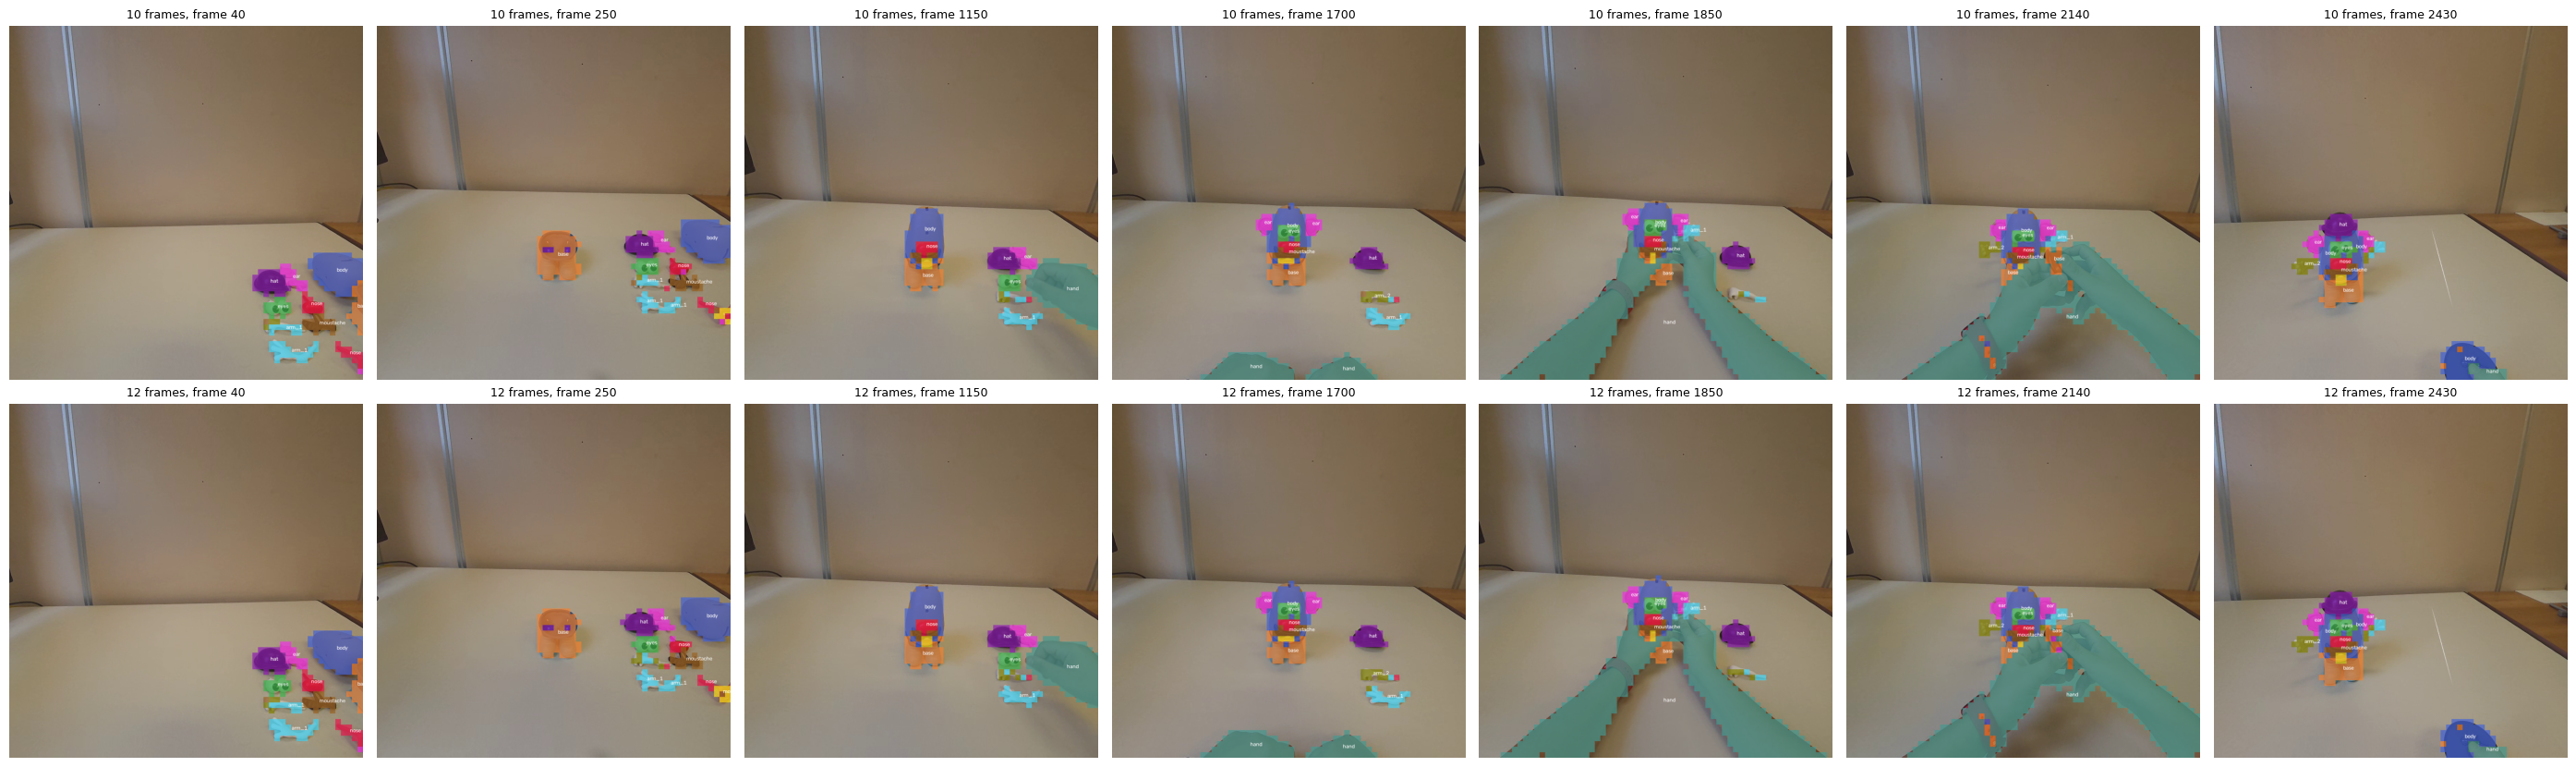

In [6]:
# The same moments of the event log, side by side: current support set (top) and 12 frames (bottom)
SHOWN = [40, 250, 1150, 1700, 1850, 2140, 2430]
cap = cv2.VideoCapture(str(VIDEO_PATH))
frames, index = {}, 0
while index <= max(SHOWN):
    ok, frame_bgr = cap.read()
    if not ok:
        break
    if index in SHOWN:
        frames[index] = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    index += 1
cap.release()
fig, axes = plt.subplots(2, len(SHOWN), figsize=(4 * len(SHOWN), 8.5))
for row, name in zip(axes, SUPPORTS):
    for ax, i in zip(row, SHOWN):
        ax.imshow(render_overlay(frames[i], labels[name][i], 5))
        ax.set_title(f"{name.split(' (')[0]}, frame {i}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
fig.savefig(OUT_DIR / "support_swap_frames.png", dpi=100, bbox_inches="tight")
plt.show()

In [7]:
# Time to classify one frame with V2 on the GPU, for both support sets (warm-up, then 30 runs alternated)
probe = evals[0]["features"]
for name in SUPPORTS:
    for _ in range(5):
        assign_labels(class_similarities_gpu(probe, *PROTOS[name]), MARGIN)
times = {name: [] for name in SUPPORTS}
for _ in range(30):
    for name in SUPPORTS:
        torch.cuda.synchronize(); t0 = time.perf_counter()
        assign_labels(class_similarities_gpu(probe, *PROTOS[name]), MARGIN)
        torch.cuda.synchronize(); times[name].append(1000 * (time.perf_counter() - t0))
display(pd.DataFrame({name: {"prototypes": len(PROTOS[name][1]), "median ms": np.median(t), "min ms": np.min(t), "max ms": np.max(t)}
                      for name, t in times.items()}).T.round(1))

,prototypes,median ms,min ms,max ms
10 frames (current),39125.0,82.1,75.9,89.6
12 frames (+ 1_disassembled_controlled_caos),47089.0,94.6,84.3,102.3
